# NeuReduce — interactive 3D failure explorer

In [1]:
%matplotlib widget
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

In [2]:
# import test set predictions
path = Path('data/predictions_test.csv')
df = pd.read_csv(path)

# some selected fingerprints of the original input
logical = df[['src_n_and', 'src_n_or', 'src_n_xor', 'src_n_not']].sum(axis=1)
arithmetic = df[['src_n_add', 'src_n_sub', 'src_n_mul']].sum(axis=1)
df['mul_pct'] = 100 * df.src_n_mul / arithmetic
df['logic_pct'] = 100 * logical / (logical + arithmetic)

# correctness supervised label
df['wrong'] = ~df['correct'].astype(bool)

# cross sections of the data according to category of operations involved in the obfuscated expression
def target_type(text):
    bitwise = any(s in text for s in '&|^~')
    arithmetic = any(s in text for s in '+-*')
    return 'Mixed' if bitwise and arithmetic else 'Bitwise only' if bitwise else 'Arithmetic only' if arithmetic else 'Atomic'

df['target_type'] = df['trg'].map(target_type)

# we tinroduce a tiny positional jitter because especially on the "multiplications per sample" the number of categories is reduced and many points ten d to be agglutinated in a short space, reducing visibility
rng = np.random.default_rng(2026)
df['blue_sample'] = rng.random(len(df))
df['jx'] = rng.uniform(-0.6, 0.6, len(df))
df['jy'] = rng.uniform(-0.35, 0.35, len(df))
df['jz'] = rng.uniform(-0.6, 0.6, len(df))
print(f'{len(df):,} expressions, {df.wrong.sum():,} failures')

10,885 expressions, 973 failures


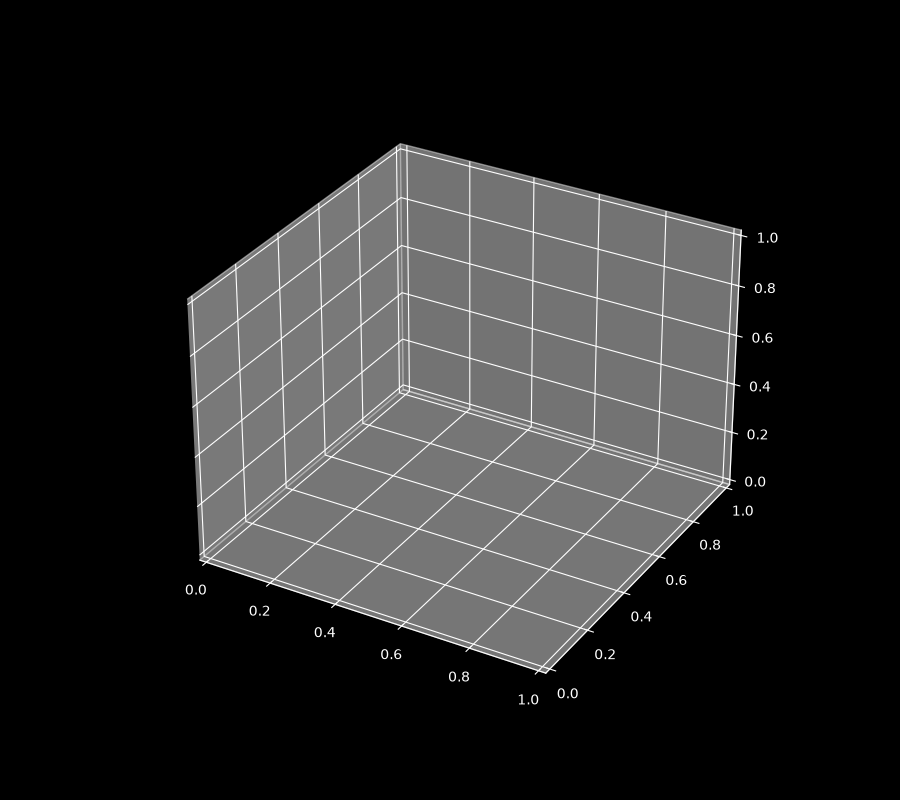

In [7]:
# point cloud plot fo the raw samples
plt.style.use('dark_background')
with plt.ioff():
    fig = plt.figure(figsize=(9, 8))
    ax = fig.add_subplot(projection='3d')

def redraw(change=None):
    selected = df if menu.value == 'All' else df[df.target_type == menu.value]
    shown = selected[selected.wrong | (selected.blue_sample < background.value / 100)]
    offset = 1 if jitter.value else 0
    ax.clear()
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.pane.fill = False
    colors = np.where(shown.wrong, 'red', 'blue')
    sizes = np.where(shown.wrong, 12, 7)
    ax.scatter(shown.mul_pct + offset*shown.jx,
               shown.src_len + offset*shown.jy,
               shown.logic_pct + offset*shown.jz,
               s=sizes, c=colors, alpha=opacity.value, depthshade=False)
    ax.set(xlabel='Multiplications among arithmetic(%)', ylabel='Input length',
           zlabel='Logical operators among all (%)',
           xlim=(0, 70), ylim=(6, 66), zlim=(10, 80))
    ax.set_box_aspect((1, 1, 1))
    ax.set_title(f'{len(shown):,} visible points, {shown.wrong.sum():,} failures')
    ax.legend(handles=[
        plt.Line2D([], [], marker='o', linestyle='', color='blue', label='Correct (sampled)'),
        plt.Line2D([], [], marker='o', linestyle='', color='red', label='Failure (all)')
    ], loc='upper left')
    fig.canvas.draw_idle()

menu = widgets.Dropdown(options=['All'] + sorted(df.target_type.unique()),
                        description='True target')
background = widgets.IntSlider(value=20, min=0, max=100, step=10,
                               description='Correct shown (%)', style={'description_width': 'initial'})
jitter = widgets.Checkbox(value=True, description='Spread overlapping dots')
opacity = widgets.FloatSlider(value=0.55, min=0.15, max=0.85, step=0.1,
                              description='Opacity')
for control in (menu, background, jitter, opacity):
    control.observe(redraw, names='value')
display(widgets.HBox([menu, background]), widgets.HBox([jitter, opacity]), fig.canvas)
redraw()

**Figure 1:** We show here a 3D plot of the suiccessfull VS wrongly deobfuscated samples according to three fingerprints of the obfuscated input expression: (X) Expression length, (Y) The fraction of multiplications among the arithmetic operations, (Z) The fraction of logical operators in the expression. We plot this with the possibility ot deaggregate the data as a function of the nature of the oprations in the true deobfuscated expression (All, Only arithmetic, Only Logical, Mixed, no-operations i.e. Atomic).
ON these data plotted singularly without further clustering, one thing which seems to emerge clearly for the non-disaggregated plot is that failures are evident for obfuscate expression length above 40 (operations). Another emergent evidence is a higher failure rate )the overall dominant color of the scatter plot is red) for the mixed, bitwise-only and atomic ground truths with respect to the arithmetic-only ground truths.
Taking a random subset of the successfull cases (20%) in order to match the absolute number of observed failures, it's possible to observe some subtler emergent patterns: for example in the non-disaggregated case (All), there is an evident dominance of failures for the quadrant identified by high context leghts, high fraction of logical operators over the total numbe rof operators and moderate (<50%) fractions of multiplications among arithmetic operations.
We also observe that data distribute in all cases along clear planes and lines, indicating some degree of correlation between the three fingerprints whcih we selected for the axes: for example arithmetic-dominated expressions seem to be also dominated by multiplications instead of additions/subtractions.

IntSlider(value=30, description='Min. examples per zone', min=10, step=10, style=SliderStyle(description_width…

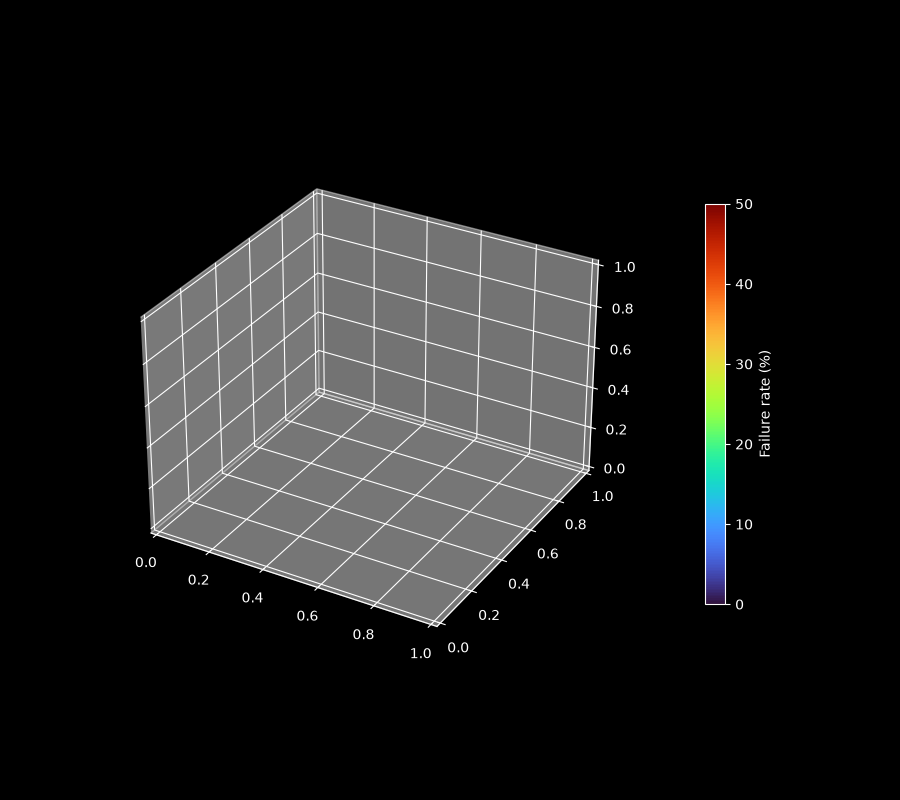

In [4]:
# We try to cluster a bit the raw data points into neighborhoods to have a more objective overview of the clustering tendencies of failures and successes respectively:
bins = {'mul_pct': [0, 15, 25, 35, 45, 70.01],
        'src_len': [6, 22, 28, 34, 40, 66],
        'logic_pct': [10, 30, 40, 50, 60, 80.01]}
for name, edges in bins.items():
    df[name + '_bin'] = pd.cut(df[name], edges, labels=False, include_lowest=True)

zones = df.groupby([name + '_bin' for name in bins], observed=True).agg(
    n=('wrong', 'size'), fail_rate=('wrong', 'mean')).reset_index()
for name, edges in bins.items():
    zones[name] = zones[name + '_bin'].map(
        lambda i: (edges[int(i)] + edges[int(i) + 1]) / 2)

with plt.ioff():
    fig2 = plt.figure(figsize=(9, 8))
    ax2 = fig2.add_subplot(projection='3d')
fig2.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(0, 50), cmap='turbo'),
              ax=ax2, label='Failure rate (%)', shrink=.65, pad=.12)

def redraw_zones(change=None):
    shown = zones[zones.n >= min_n.value]
    ax2.clear()
    for axis in (ax2.xaxis, ax2.yaxis, ax2.zaxis):
        axis.pane.fill = False
    ax2.scatter(shown.mul_pct, shown.src_len, shown.logic_pct,
                s=30 + .6*shown.n, c=100*shown.fail_rate,
                vmin=0, vmax=50, cmap='turbo', alpha=.85, depthshade=False)
    ax2.set(xlim=(0, 70), ylim=(6, 66), zlim=(10, 80),
            xlabel='Multiplications among arithmetic (%)',
            ylabel='Input length', zlabel='Logical operators among all (%)',
            title=f'{len(shown)} regions covering {shown.n.sum():,} of {len(df):,} examples')
    ax2.set_box_aspect((1, 1, 1))
    fig2.canvas.draw_idle()

min_n = widgets.IntSlider(value=30, min=10, max=100, step=10,
                          description='Min. examples per zone',
                          style={'description_width': 'initial'})
min_n.observe(redraw_zones, names='value')
display(min_n, fig2.canvas)
redraw_zones()

**Figure 2:** We can now clearly see some of the things already visible in the full plot fo Figure 1, i.e. that there is an obivious tendency to fail the deobfuscation for long inpout expressions (>40) and for a high dominance of logical over arithmetic operations in the expression; but now we can also observe a non-trivial tendecy to a worse perforformance in a cluster identified by moderate input lengths (<40) jointly with a high dominance of multiplications. Many of the observetions we have done so far can of coure be trivally related ot the natue of the trainign dataset, which we are not taking into account at all for this analysis.